In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
df = pd.read_csv("dataset.csv")
print(df.info())
print(df.isna().sum())
print(df.duplicated().sum())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [4]:
df = df.drop_duplicates(subset=["track_id"]).copy()


features = [ "acousticness", "danceability", "duration_ms", "energy", "instrumentalness", "liveness", "loudness", "speechiness", "tempo", "valence"]


df = df.dropna(subset=features + ["popularity"]).copy()


df = df.reset_index(drop=True)

#I am separating features form the target
X = df[features].copy()
y = df["popularity"]

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=features,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=features,
    index=X_test.index
)


df.to_csv("spotify_regression_cleaned.csv", index=False)

print("Training size:", X_train_scaled.shape)
print("Testing size:", X_test_scaled.shape)
print(X_train_scaled.head())

Training size: (71792, 10)
Testing size: (17949, 10)
       acousticness  danceability  duration_ms    energy  instrumentalness  \
30418      0.929728      0.016915    -0.031168 -0.652908         -0.536779   
5875      -0.969089     -2.343117     0.254081  1.338204         -0.536521   
68198     -0.966385     -0.820698    -0.389077  1.194033         -0.536513   
57668     -0.817068      1.850609    -0.611248  0.025083         -0.536694   
71420      0.158952      1.052613     0.557717  0.364079         -0.536779   

       liveness  loudness  speechiness     tempo   valence  
30418 -0.586460  0.145934    -0.343737 -0.319299 -1.342302  
5875  -0.701704  0.856036     0.876306 -1.859872 -0.491143  
68198  1.370123  0.988667    -0.282074 -0.237816 -0.209957  
57668 -0.140851  0.765580    -0.182533 -1.133433  0.451211  
71420 -0.099875  0.443830     0.603228 -0.732860  0.629803  


In [6]:
#audio
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_scaled, y_train)
baseline_pred = baseline.predict(X_test_scaled)

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred = linear_model.predict(X_test_scaled)

def evaluate(name, actual, predictions):
    return {
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "MAE": mean_absolute_error(actual, predictions),
        "R²": r2_score(actual, predictions)
    }

results = [
    evaluate("Mean baseline", y_test, baseline_pred),
    evaluate("Audio only", y_test, y_pred),
]
print(pd.DataFrame(results).round(3).to_string(index=False))

        Model   RMSE    MAE     R²
Mean baseline 20.438 17.121 -0.000
   Audio only 20.142 16.595  0.029


In [7]:
X_train_extended = X_train_scaled.copy()
X_test_extended = X_test_scaled.copy()

# Add binary explicit status
X_train_extended["explicit"] = df.loc[X_train.index, "explicit"].astype(int)
X_test_extended["explicit"] = df.loc[X_test.index, "explicit"].astype(int)

# One-hot encode genres using pandas only
train_genres = pd.get_dummies(
    df.loc[X_train.index, "track_genre"], prefix="genre", dtype=int
)
test_genres = pd.get_dummies(
    df.loc[X_test.index, "track_genre"], prefix="genre", dtype=int
)
test_genres = test_genres.reindex(columns=train_genres.columns, fill_value=0)

X_train_extended = pd.concat([X_train_extended, train_genres], axis=1)
X_test_extended = pd.concat([X_test_extended, test_genres], axis=1)

linear_model_extended = LinearRegression()
linear_model_extended.fit(X_train_extended, y_train)
y_pred_extended = linear_model_extended.predict(X_test_extended)

results.append(evaluate("Audio + explicit + genre", y_test, y_pred_extended))
print(pd.DataFrame(results).round(3).to_string(index=False))

                   Model   RMSE    MAE     R²
           Mean baseline 20.438 17.121 -0.000
              Audio only 20.142 16.595  0.029
Audio + explicit + genre 16.851 12.011  0.320


         Feature  Coefficient
instrumentalness    -2.935252
         valence    -2.243721
     speechiness    -1.387447
    acousticness    -0.629326
          energy    -0.536600
     duration_ms    -0.461156
        liveness     0.079326
           tempo     0.153891
        loudness     0.388827
    danceability     1.845680


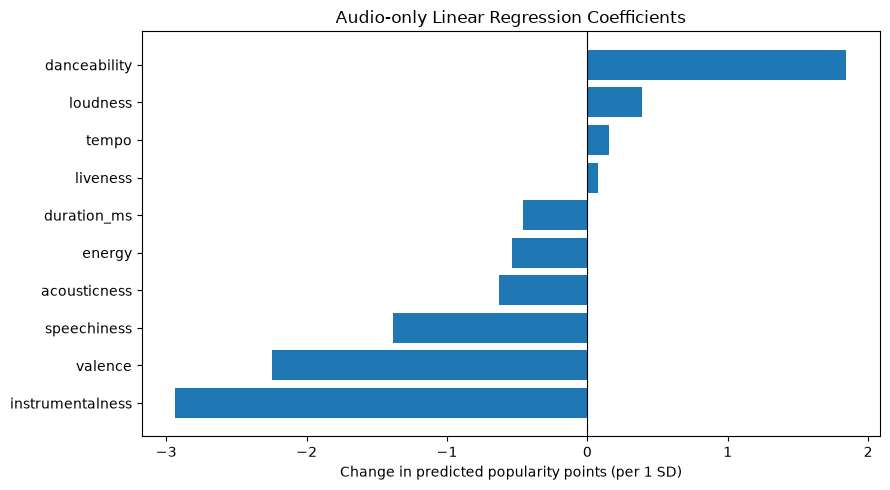

In [8]:
coefs = pd.DataFrame({
    "Feature": features,
    "Coefficient": linear_model.coef_
}).sort_values("Coefficient")
print(coefs.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(coefs["Feature"], coefs["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Change in predicted popularity points (per 1 SD)")
plt.title("Audio-only Linear Regression Coefficients")
plt.tight_layout()
plt.show()

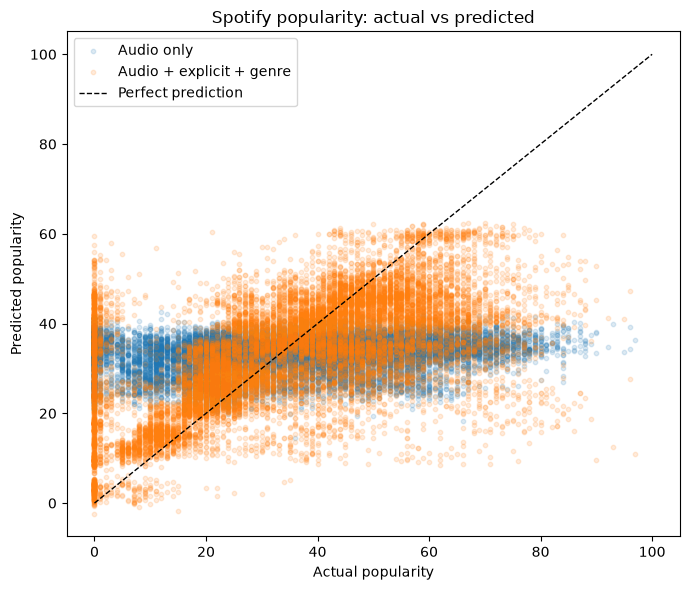

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred, alpha=0.15, s=10, label="Audio only")
ax.scatter(y_test, y_pred_extended, alpha=0.15, s=10, label="Audio + explicit + genre")
ax.plot([0, 100], [0, 100], "k--", linewidth=1, label="Perfect prediction")
ax.set(xlabel="Actual popularity", ylabel="Predicted popularity",
       title="Spotify popularity: actual vs predicted")
ax.legend()
plt.tight_layout()
plt.show()